# 01 · Entendimiento de los datos, EDA y limpieza

**Fase CRISP-DM:** entendimiento y preparación de los datos.

Se trabaja con el dataset **CICIoMT2024** (tráfico Wi-Fi y MQTT de
dispositivos médicos) y tres tipos de tráfico:

| `clase` | Tráfico | `etiqueta` (binaria) |
|---|---|---|
| 0 | Benigno | 0 |
| 1 | DDoS SYN | 1 |
| 2 | DDoS UDP | 1 |

Los CSV deben estar en `data/raw/CICIoMT2024/train/` y `.../test/`
(ver `DESCARGA_DATOS.txt`). Este notebook genera
`data/processed/train_limpio.parquet` y `data/processed/test_limpio.parquet`.

In [1]:
import sys
from pathlib import Path

# Permite importar src/ al ejecutar desde notebooks/ o desde la raíz
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ.resolve()))

from src.evaluate import configurar_graficos
configurar_graficos()

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data_loader import (
    CLASES, verificar_archivos, cargar_particion, columnas_caracteristicas,
    resumen_calidad, limpiar, guardar_procesado,
)

pd.set_option("display.max_columns", 60)
display(verificar_archivos())

,Partición,Clase,Archivo,Disponible
0,train,Benigno,Benign_train.pcap.csv,True
1,train,DDoS SYN,TCP_IP-DDoS-SYN1_train.pcap.csv,True
2,train,DDoS UDP,TCP_IP-DDoS-UDP1_train.pcap.csv,True
3,test,Benigno,Benign_test.pcap.csv,True
4,test,DDoS SYN,TCP_IP-DDoS-SYN_test.pcap.csv,True
5,test,DDoS UDP,TCP_IP-DDoS-UDP1_test.pcap.csv,True


## 1. Estructura de los archivos

In [2]:
train = cargar_particion("train")
test = cargar_particion("test")
variables = columnas_caracteristicas(train)

print("Entrenamiento — filas y columnas:", train.shape)
print("Prueba oficial — filas y columnas:", test.shape)
print("Mismas columnas y orden en train y test:",
      list(train.columns) == list(test.columns))

print(f"\n{len(variables)} variables de flujo:")
print(variables)

print("\nTipos de datos:")
print(train[variables].dtypes.value_counts())

Entrenamiento — filas y columnas: (598292, 47)
Prueba oficial — filas y columnas: (415658, 47)
Mismas columnas y orden en train y test: True

45 variables de flujo:
['Header_Length', 'Protocol Type', 'Duration', 'Rate', 'Srate', 'Drate', 'fin_flag_number', 'syn_flag_number', 'rst_flag_number', 'psh_flag_number', 'ack_flag_number', 'ece_flag_number', 'cwr_flag_number', 'ack_count', 'syn_count', 'fin_count', 'rst_count', 'HTTP', 'HTTPS', 'DNS', 'Telnet', 'SMTP', 'SSH', 'IRC', 'TCP', 'UDP', 'DHCP', 'ARP', 'ICMP', 'IGMP', 'IPv', 'LLC', 'Tot sum', 'Min', 'Max', 'AVG', 'Std', 'Tot size', 'IAT', 'Number', 'Magnitue', 'Radius', 'Covariance', 'Variance', 'Weight']

Tipos de datos:
float64    45
Name: count, dtype: int64


In [3]:
display(train.groupby("clase").head(2).set_index("clase").rename(index=CLASES))

,Header_Length,Protocol Type,Duration,Rate,Srate,Drate,fin_flag_number,syn_flag_number,rst_flag_number,psh_flag_number,ack_flag_number,ece_flag_number,cwr_flag_number,ack_count,syn_count,fin_count,rst_count,HTTP,HTTPS,DNS,Telnet,SMTP,SSH,IRC,TCP,UDP,DHCP,ARP,ICMP,IGMP,IPv,LLC,Tot sum,Min,Max,AVG,Std,Tot size,IAT,Number,Magnitue,Radius,Covariance,Variance,Weight,etiqueta
clase,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
Benigno,134.30,7.1,64.0,40415.288318,40415.288318,0.0,0.0,0.0,0.0,0.5,0.90,0.0,0.0,0.0,0.0,0.0,1.30,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.9,0.1,0.0,0.0,0.0,0.0,1.0,1.0,577.50,82.5,214.00,119.317540,48.225852,95.30,1.694641e+08,5.5,15.312231,68.201654,2644.242675,0.90,38.50,0
Benigno,137.00,4.7,49.9,58749.191833,58749.191833,0.0,0.0,0.0,0.0,0.2,0.50,0.0,0.0,0.0,0.0,0.0,0.90,0.0,0.1,0.0,0.0,0.0,0.0,0.0,0.5,0.1,0.0,0.4,0.0,0.0,0.6,0.6,1420.20,49.2,310.80,90.890653,59.753361,125.60,1.694641e+08,13.5,13.468364,84.997147,5328.483794,1.00,244.60,0
DDoS SYN,55.12,6.0,64.0,0.000000,0.000000,0.0,0.0,1.0,0.0,0.0,0.28,0.0,0.0,0.0,1.0,0.0,0.28,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,576.84,54.8,55.12,54.882626,0.133949,55.12,1.016356e+08,9.5,10.475697,0.189007,0.229786,0.08,141.55,1
DDoS SYN,55.40,6.0,64.0,0.000000,0.000000,0.0,0.0,1.0,0.0,0.0,0.35,0.0,0.0,0.0,1.0,0.0,0.35,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,583.20,55.4,55.60,55.567706,0.071105,55.40,8.469633e+07,9.5,10.540654,0.099125,0.101392,0.05,141.55,1
DDoS UDP,1267.00,17.0,64.0,230960.275963,230960.275963,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,525.00,50.0,50.00,50.000000,0.000000,50.00,1.016359e+08,9.5,10.000000,0.000000,0.000000,0.00,141.55,1
DDoS UDP,2364.50,17.0,64.0,450601.451726,450601.451726,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,525.00,50.0,50.00,50.000000,0.000000,50.00,8.469660e+07,9.5,10.000000,0.000000,0.000000,0.00,141.55,1


El dataset no incluye direcciones IP, puertos ni marcas de tiempo:
todas las columnas son estadísticas de flujo (tamaños, tasas, banderas
TCP e indicadores de protocolo), como propone el informe.

## 2. Distribución de clases

,Entrenamiento,Prueba oficial,Entrenamiento (proporción),Prueba oficial (proporción)
clase,,,,
Benigno,192732,37607,0.322,0.090
DDoS SYN,199390,172397,0.333,0.415
DDoS UDP,206170,205654,0.345,0.495


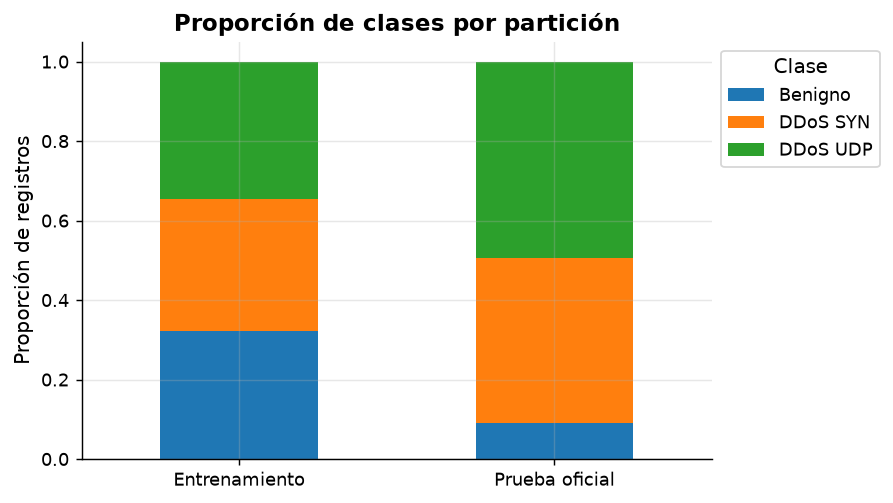

In [4]:
conteo = pd.DataFrame({
    "Entrenamiento": train["clase"].value_counts(),
    "Prueba oficial": test["clase"].value_counts(),
}).sort_index().rename(index=CLASES)
proporcion = conteo / conteo.sum()

display(conteo.join(proporcion.round(3).add_suffix(" (proporción)")))

proporcion.T.plot.bar(
    stacked=True, figsize=(7, 4), rot=0,
    title="Proporción de clases por partición"
)
plt.ylabel("Proporción de registros")
plt.legend(title="Clase", bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

Las proporciones de clase no son iguales en entrenamiento y en la prueba
oficial. En la prueba predomina el tráfico de ataque, por lo que la
accuracy y la precisión de DDoS pueden verse altas incluso con un
modelo trivial. Por eso se reportan también F1 macro, recall por clase
y tasa de falsos positivos.

## 3. Calidad de los datos

In [5]:
calidad = pd.DataFrame({
    "Entrenamiento": resumen_calidad(train),
    "Prueba oficial": resumen_calidad(test),
})
display(calidad)

faltantes = train[variables].isna().sum()
print("Columnas con valores faltantes en entrenamiento:")
print(faltantes[faltantes > 0])

print("\nDuplicados por clase en entrenamiento:")
print(train.loc[train.duplicated(), "clase"].map(CLASES).value_counts())

,Entrenamiento,Prueba oficial
Registros,598292,415658
Valores faltantes,0,0
Valores infinitos,0,0
Filas duplicadas,0,0
Filas contradictorias,0,0


Columnas con valores faltantes en entrenamiento:
Series([], dtype: int64)

Duplicados por clase en entrenamiento:


Series([], Name: count, dtype: int64)


## 4. Variables constantes y redundantes

In [6]:
resumen = pd.DataFrame({
    "Valores distintos": train[variables].nunique(),
    "Valor más frecuente (proporción)": train[variables].apply(
        lambda s: s.value_counts(normalize=True).iloc[0]
    ),
}).sort_values("Valores distintos")
display(resumen.head(15).round(4))

identicas = [
    (a, b)
    for i, a in enumerate(variables)
    for b in variables[i + 1:]
    if train[a].equals(train[b])
]
print("Pares de columnas idénticas:", identicas)

,Valores distintos,Valor más frecuente (proporción)
Drate,1,1.0000
cwr_flag_number,3,1.0000
SSH,4,0.9995
IRC,4,0.9995
ece_flag_number,4,1.0000
Telnet,4,0.9995
SMTP,4,0.9995
DHCP,5,1.0000
IGMP,8,0.9998
HTTP,15,0.9906


Pares de columnas idénticas: [('Rate', 'Srate'), ('IPv', 'LLC')]


Las columnas constantes no aportan información y las idénticas son
redundantes. Se eliminan en el notebook 02, decidiendo solo con el
conjunto de entrenamiento.

## 5. Estadísticas por clase

In [7]:
destacadas = [
    "Header_Length", "Protocol Type", "Duration", "Rate",
    "syn_flag_number", "ack_flag_number", "rst_flag_number",
    "TCP", "UDP", "Tot size", "AVG", "Std", "IAT",
]
display(
    train.groupby("clase")[destacadas].median()
    .rename(index=CLASES).T.round(3)
    .rename_axis("Mediana por clase")
)

clase,Benigno,DDoS SYN,DDoS UDP
Mediana por clase,,,
Header_Length,1.705341e+05,6.716000e+01,2.471300e+04
Protocol Type,6.000000e+00,6.000000e+00,1.700000e+01
Duration,6.400000e+01,6.400000e+01,6.400000e+01
Rate,1.652000e+00,1.128700e+01,2.033509e+04
syn_flag_number,0.000000e+00,1.000000e+00,0.000000e+00
ack_flag_number,1.000000e+00,0.000000e+00,0.000000e+00
rst_flag_number,0.000000e+00,0.000000e+00,0.000000e+00
TCP,1.000000e+00,1.000000e+00,0.000000e+00
UDP,0.000000e+00,0.000000e+00,1.000000e+00


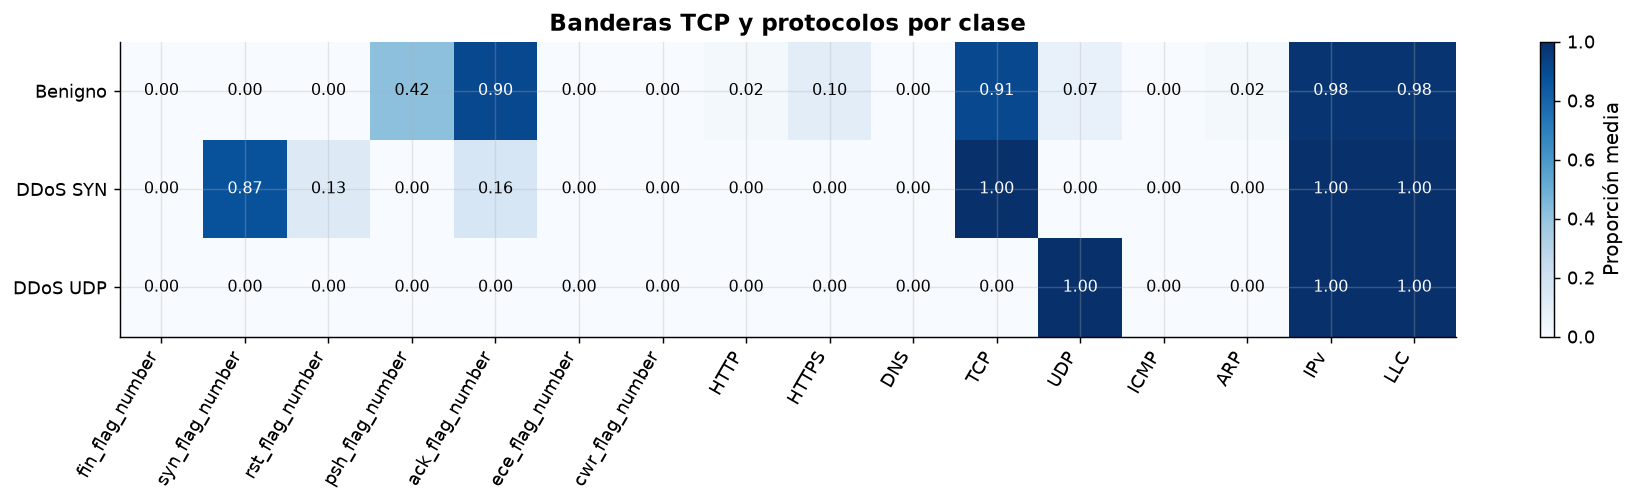

In [8]:
indicadores = (
    [c for c in variables if c.endswith("_flag_number")]
    + ["HTTP", "HTTPS", "DNS", "TCP", "UDP", "ICMP", "ARP", "IPv", "LLC"]
)
medias = train.groupby("clase")[indicadores].mean().rename(index=CLASES)

fig, ax = plt.subplots(figsize=(14, 4))
im = ax.imshow(medias, cmap="Blues", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(indicadores)), indicadores, rotation=60, ha="right")
ax.set_yticks(range(len(medias)), medias.index)
for i in range(medias.shape[0]):
    for j in range(medias.shape[1]):
        valor = medias.iat[i, j]
        ax.text(j, i, f"{valor:.2f}", ha="center", va="center", fontsize=9,
                color="white" if valor > 0.6 else "black")
fig.colorbar(im, ax=ax, label="Proporción media")
ax.set_title("Banderas TCP y protocolos por clase")
plt.tight_layout()
plt.show()

Este gráfico muestra qué banderas y protocolos caracterizan a cada
ataque. Se espera que DDoS SYN tenga una alta proporción de la bandera
SYN y DDoS UDP una alta proporción de UDP. Si una sola variable separa
casi perfectamente las clases, el modelo puede depender de ese "atajo",
lo que es relevante al evaluar la generalización entre dominios.

## 6. Distribuciones por clase

Se usa una muestra de hasta 50.000 registros por clase y la escala
`log(1 + x)`, porque variables como `Rate` tienen colas muy largas.

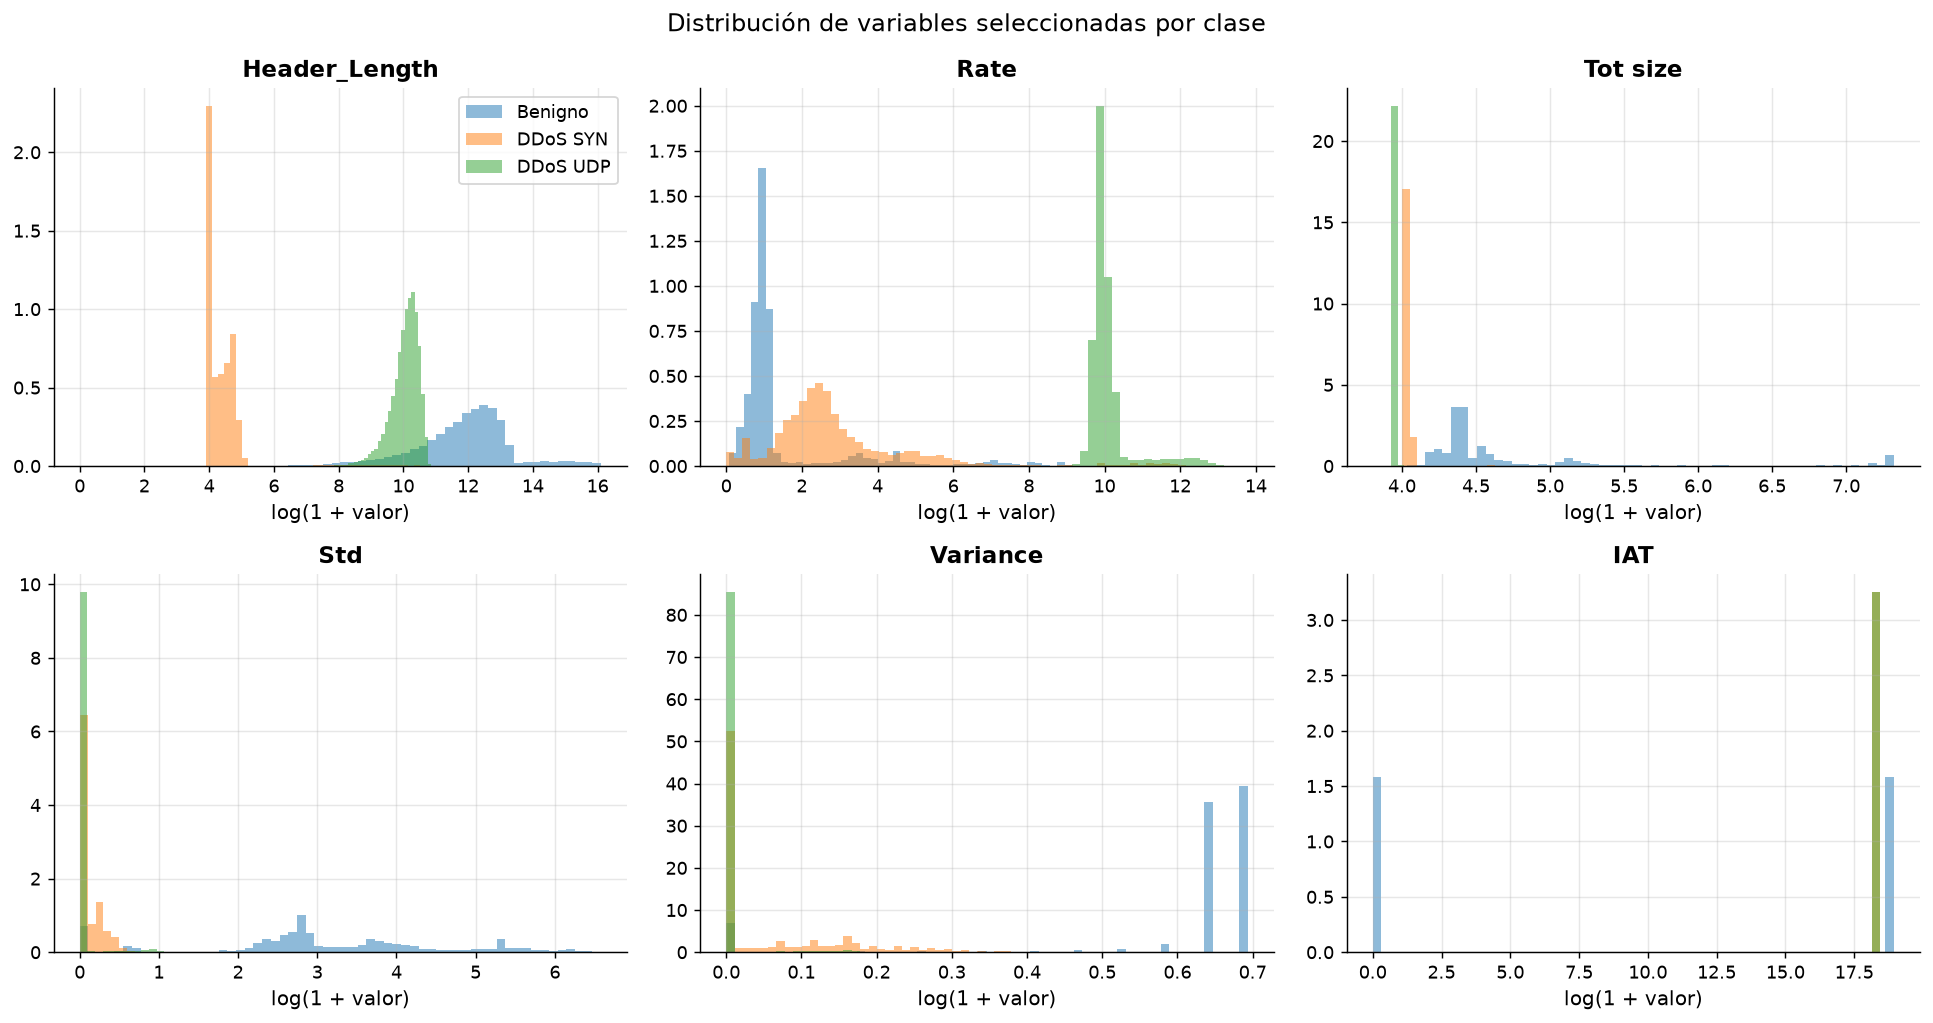

In [9]:
muestra = pd.concat([
    g.sample(min(len(g), 50_000), random_state=42)
    for _, g in train.groupby("clase")
]).replace([np.inf, -np.inf], np.nan)

# Duration (TTL) es casi constante; IAT se incluye para mostrar su separación por captura
columnas_grafico = ["Header_Length", "Rate", "Tot size", "Std", "Variance", "IAT"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, columna in zip(axes.ravel(), columnas_grafico):
    for clase, nombre in CLASES.items():
        valores = muestra.loc[muestra["clase"] == clase, columna].dropna()
        ax.hist(np.log1p(valores.clip(lower=0)), bins=60, alpha=0.5,
                density=True, label=nombre)
    ax.set_title(columna)
    ax.set_xlabel("log(1 + valor)")
axes[0, 0].legend()
fig.suptitle("Distribución de variables seleccionadas por clase")
plt.tight_layout()
plt.show()

## 7. Correlación entre variables

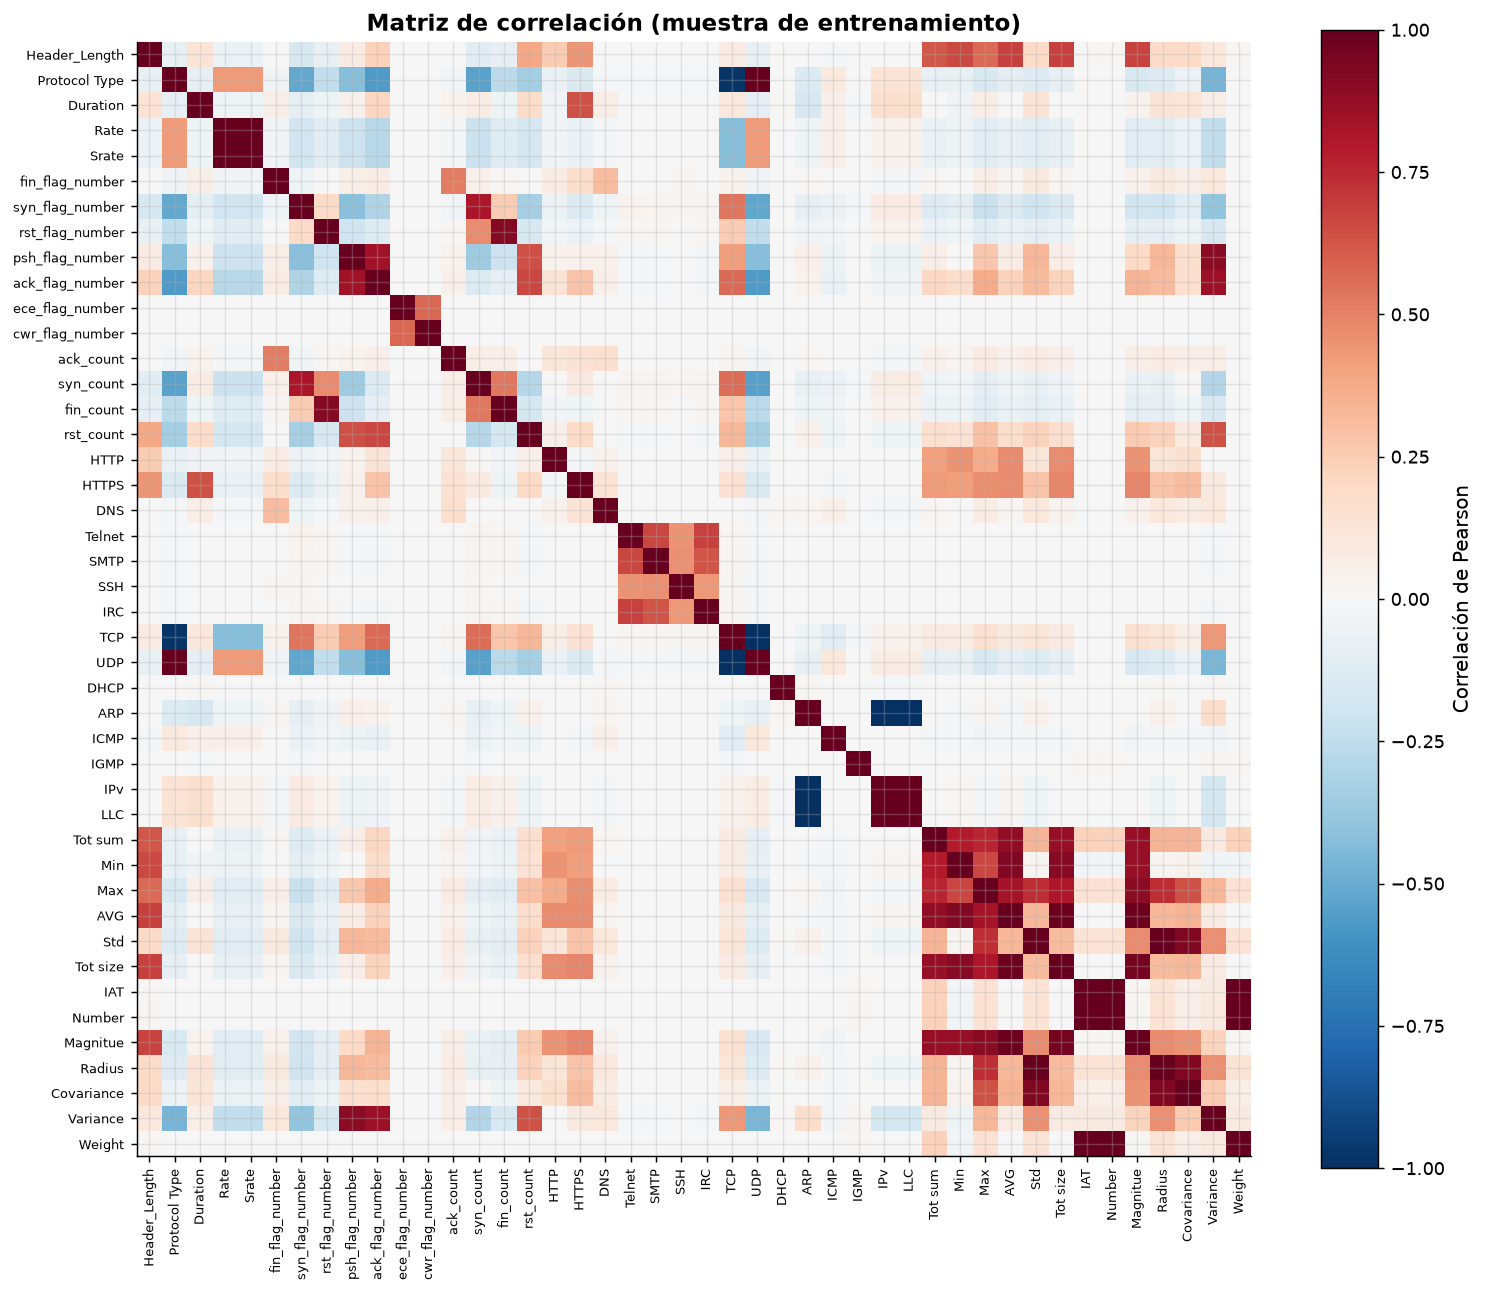

Correlación
Rate          Srate          1.0000
IPv           LLC            1.0000
ARP           IPv           -1.0000
              LLC           -1.0000
Number        Weight         1.0000
Std           Radius         0.9999
IAT           Weight         0.9993
              Number         0.9992
Protocol Type UDP            0.9979
TCP           UDP           -0.9929
Protocol Type TCP           -0.9832
AVG           Magnitue       0.9826
              Tot size       0.9795
Tot size      Magnitue       0.9604

In [10]:
no_constantes = [c for c in variables if muestra[c].nunique() > 1]
correlacion = muestra[no_constantes].corr()

fig, ax = plt.subplots(figsize=(12, 10))
im = ax.imshow(correlacion, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(no_constantes)), no_constantes, rotation=90, fontsize=7)
ax.set_yticks(range(len(no_constantes)), no_constantes, fontsize=7)
fig.colorbar(im, ax=ax, label="Correlación de Pearson")
ax.set_title("Matriz de correlación (muestra de entrenamiento)")
plt.tight_layout()
plt.show()

pares = correlacion.where(
    np.triu(np.ones(correlacion.shape, dtype=bool), k=1)
).stack()
display(
    pares[pares.abs() > 0.95]
    .sort_values(key=np.abs, ascending=False)
    .rename("Correlación").to_frame().round(4)
)

## 8. Limpieza y guardado

- **Entrenamiento:** infinitos → NaN, se eliminan filas con
  características idénticas y clases distintas, y duplicados exactos.
  Así una misma fila no puede quedar en entrenamiento y validación.
- **Prueba oficial:** solo infinitos → NaN. No se eliminan filas, para
  evaluar el tráfico tal como se registró.

Los valores NaN se imputan con la mediana dentro de los pipelines de
modelado, ajustando la imputación solo con entrenamiento.

In [11]:
train_limpio, informe_train = limpiar(train, eliminar_filas=True)
test_limpio, informe_test = limpiar(test, eliminar_filas=False)

display(pd.DataFrame({
    "Entrenamiento": informe_train,
    "Prueba oficial": informe_test,
}))

print("Registros de entrenamiento por clase tras la limpieza:")
print(train_limpio["clase"].map(CLASES).value_counts())

print("\nGuardado:", guardar_procesado(train_limpio, "train_limpio"))
print("Guardado:", guardar_procesado(test_limpio, "test_limpio"))

,Entrenamiento,Prueba oficial
Registros iniciales,598292,415658
Contradictorias eliminadas,0,0
Duplicados eliminados,0,0
Registros finales,598292,415658


Registros de entrenamiento por clase tras la limpieza:
clase
DDoS UDP    206170
DDoS SYN    199390
Benigno     192732
Name: count, dtype: int64



Guardado: /Users/makise/Documents/GitHub/Data-Science/data/processed/train_limpio.parquet


Guardado: /Users/makise/Documents/GitHub/Data-Science/data/processed/test_limpio.parquet


## Conclusiones del EDA

Completar con los resultados obtenidos al ejecutar el notebook:

1. **Calidad:** cantidad de faltantes, infinitos, duplicados y filas
   contradictorias, y cuántos registros se eliminaron.
2. **Desbalance:** diferencia de proporciones entre entrenamiento y
   prueba oficial, y por qué se usan F1 macro y tasa de falsos positivos.
3. **Separabilidad:** variables que distinguen claramente cada ataque
   (banderas SYN, protocolo UDP, tasas) y el riesgo de "atajos".
4. **Redundancia:** columnas constantes, idénticas o muy correlacionadas
   que se tratarán en el notebook 02.